# Análisis Exploratorio de Datos (EDA) - Rendimiento Académico

# 1.Importación librerías

In [1]:
import sys
sys.path.append('..') #para poder importar la carpeta src desde notebooks/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_prep import Preprocesador

# 2.Importación fuente de datos

In [2]:
#Usamos la clase Preprocesador para cargar y unir las dos materias (sin repetir código)
prep = Preprocesador()
df = prep.cargar_datos()

#Agregamos las variables derivadas y el nivel de riesgo para poder analizarlos también
prep.crear_variables_derivadas()
prep.crear_nivel_riesgo()
df.shape

(1044, 37)

In [3]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,Walc,health,absences,G1,G2,G3,materia,promedio_notas,tasa_ausencias,nivel_riesgo
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,1,3,6,5,6,6,matematicas,5.5,0.064516,4
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,1,3,4,5,5,6,matematicas,5.0,0.043011,4
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,3,10,7,8,10,matematicas,7.5,0.107527,3
3,GP,F,15,U,GT3,T,4,2,health,services,...,1,5,2,15,14,15,matematicas,14.5,0.021505,1
4,GP,F,16,U,GT3,T,3,3,other,other,...,2,5,4,6,10,10,matematicas,8.0,0.043011,3


# 3.Descripción general de los datos

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1044 entries, 0 to 1043
Data columns (total 37 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   school          1044 non-null   str    
 1   sex             1044 non-null   str    
 2   age             1044 non-null   int64  
 3   address         1044 non-null   str    
 4   famsize         1044 non-null   str    
 5   Pstatus         1044 non-null   str    
 6   Medu            1044 non-null   int64  
 7   Fedu            1044 non-null   int64  
 8   Mjob            1044 non-null   str    
 9   Fjob            1044 non-null   str    
 10  reason          1044 non-null   str    
 11  guardian        1044 non-null   str    
 12  traveltime      1044 non-null   int64  
 13  studytime       1044 non-null   int64  
 14  failures        1044 non-null   int64  
 15  schoolsup       1044 non-null   str    
 16  famsup          1044 non-null   str    
 17  paid            1044 non-null   str    
 18 

In [5]:
df.describe().transpose() #Principales datos estadísticos del dataframe, la variable objetivo es G3

,count,mean,std,min,25%,50%,75%,max
age,1044.0,16.726054,1.239975,15.0,16.0,17.000000,18.000000,22.000000
Medu,1044.0,2.603448,1.124907,0.0,2.0,3.000000,4.000000,4.000000
Fedu,1044.0,2.387931,1.099938,0.0,1.0,2.000000,3.000000,4.000000
traveltime,1044.0,1.522989,0.731727,1.0,1.0,1.000000,2.000000,4.000000
studytime,1044.0,1.970307,0.834353,1.0,1.0,2.000000,2.000000,4.000000
failures,1044.0,0.264368,0.656142,0.0,0.0,0.000000,0.000000,3.000000
famrel,1044.0,3.935824,0.933401,1.0,4.0,4.000000,5.000000,5.000000
freetime,1044.0,3.201149,1.031507,1.0,3.0,3.000000,4.000000,5.000000
goout,1044.0,3.156130,1.152575,1.0,2.0,3.000000,4.000000,5.000000
Dalc,1044.0,1.494253,0.911714,1.0,1.0,1.000000,2.000000,5.000000


In [6]:
#¿Cuántos estudiantes hay por materia y por escuela?
pd.crosstab(df['materia'], df['school'], margins=True)

school,GP,MS,All
materia,,,
matematicas,349,46,395
portugues,423,226,649
All,772,272,1044


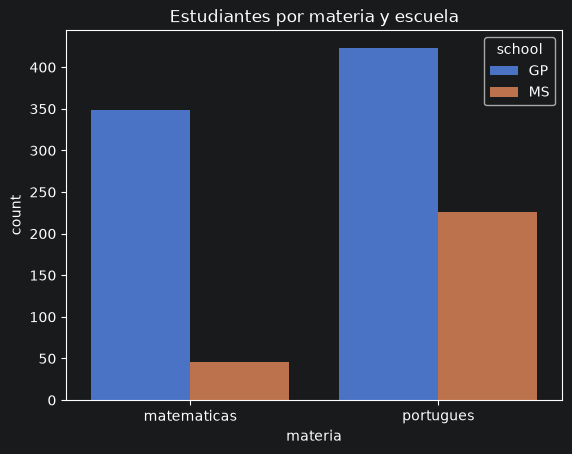

In [7]:
#Gráfico de estudiantes por materia y escuela
sns.countplot(x='materia', hue='school', data=df)
plt.title('Estudiantes por materia y escuela')
plt.show()

**Observaciones generales**

- El dataset tiene 1044 registros: 395 de matemáticas y 649 de portugués.
- La mayoría de los estudiantes son de la escuela Gabriel Pereira (GP: 772) y el resto de Mousinho da Silveira (MS: 272).
- La nota final G3 tiene un promedio de 11.3 sobre 20, con una mediana de 11

# 4.Variable objetivo: nota final (G3)

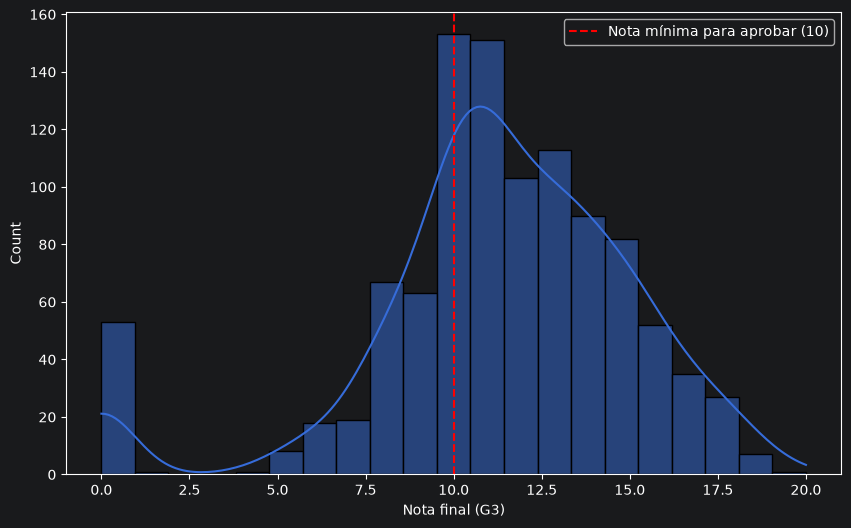

In [8]:
#Distribución de la nota final G3 (escala 0 a 20)
plt.figure(figsize=(10,6))
sns.histplot(df['G3'], bins=21, kde=True)
plt.axvline(10, color='r', linestyle='--', label='Nota mínima para aprobar (10)')
plt.xlabel('Nota final (G3)')
plt.legend()
plt.show()

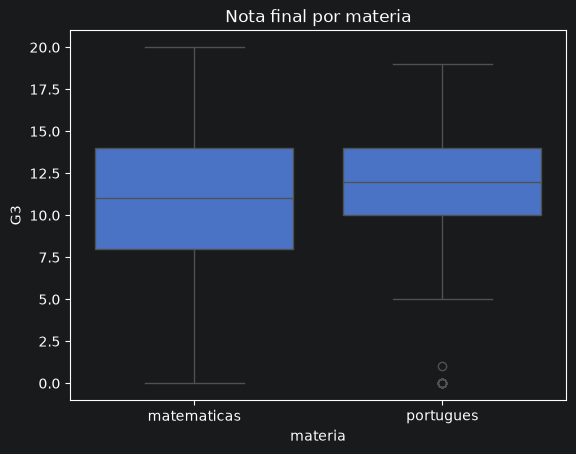

In [9]:
#¿Hay diferencia en la nota final entre matemáticas y portugués?
sns.boxplot(x='materia', y='G3', data=df)
plt.title('Nota final por materia')
plt.show()

In [10]:
df.groupby('materia')['G3'].agg(['mean','median','std'])

,mean,median,std
materia,,,
matematicas,10.415190,11.0,4.581443
portugues,11.906009,12.0,3.230656


In [11]:
#Porcentaje de estudiantes que reprueban (G3 < 10) por materia
(df['G3'] < 10).groupby(df['materia']).mean() * 100

materia
matematicas    32.911392
portugues      15.408320
Name: G3, dtype: float64

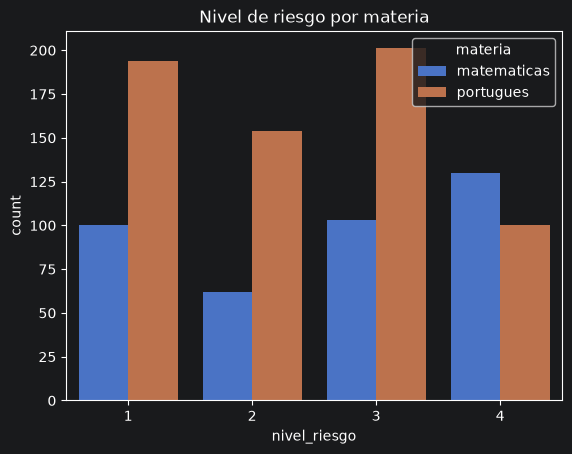

In [12]:
#Distribución del nivel de riesgo (1 = Sin riesgo, 2 = Bajo, 3 = Medio, 4 = Alto)
sns.countplot(x='nivel_riesgo', hue='materia', data=df)
plt.title('Nivel de riesgo por materia')
plt.show()

**Observaciones de la nota final (G3)**

- La nota más frecuente es 10 y la mayoría de los estudiantes está entre 8 y 15.
- Hay un grupo separado de 53 estudiantes con nota 0, que probablemente abandonaron o no se presentaron al examen final.
- El 22 % de los estudiantes reprueba (G3 < 10).
- Matemáticas es más difícil: promedio de 10.4 contra 11.9 en portugués, sus notas están más dispersas, y reprueba el 32.9 % en matemáticas contra el 15.4 % en portugués.
- En el nivel de riesgo alto (4) hay más estudiantes de matemáticas que de portugués, aunque portugués tiene muchos más estudiantes en total.

# 5.Notas parciales (G1 y G2)

In [13]:
#Correlación entre las tres notas
df[['G1','G2','G3']].corr()

,G1,G2,G3
G1,1.000000,0.858739,0.809142
G2,0.858739,1.000000,0.910743
G3,0.809142,0.910743,1.000000


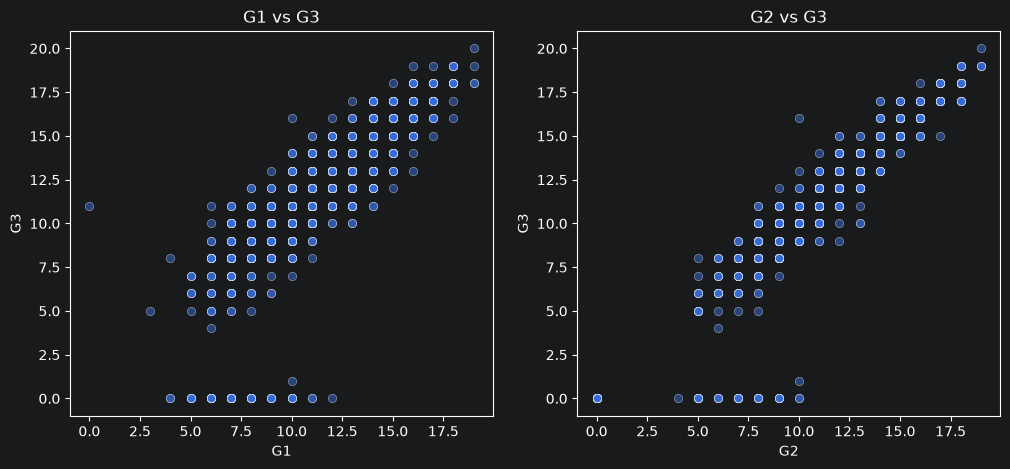

In [14]:
#Visualizar la relación de las notas parciales con la nota final
fig, axes = plt.subplots(1, 2, figsize=(12,5))
sns.scatterplot(x='G1', y='G3', data=df, ax=axes[0], alpha=0.5)
axes[0].set_title('G1 vs G3')
sns.scatterplot(x='G2', y='G3', data=df, ax=axes[1], alpha=0.5)
axes[1].set_title('G2 vs G3')
plt.show()

In [15]:
#¿Qué porcentaje de estudiantes tiene una nota final igual o muy cercana (±1 punto) a la del segundo periodo?
print('G3 igual a G2:', round((df['G2'] == df['G3']).mean() * 100, 1), '%')
print('G3 a ±1 punto de G2:', round(((df['G3'] - df['G2']).abs() <= 1).mean() * 100, 1), '%')

G3 igual a G2: 46.1 %
G3 a ±1 punto de G2: 88.3 %


**Observaciones de las notas parciales**

- G1 y G2 tienen una correlación muy alta con la nota final (0.81 y 0.91).
- El 46 % de los estudiantes tiene exactamente la misma nota en G2 y en G3, y el 88 % está a un punto o menos.
- En los gráficos se ve una línea casi recta: quien va bien en el periodo, termina bien el año.
- Los puntos en G3 = 0 con G1 o G2 mayores que 0 son los estudiantes que abandonaron: tenían nota durante el año, pero no en el final.
- Por eso el Modelo 1 se compara con y sin G1/G2: con ellas la predicción es muy buena, pero llega tarde para una alerta temprana.

# 6.Factores académicos

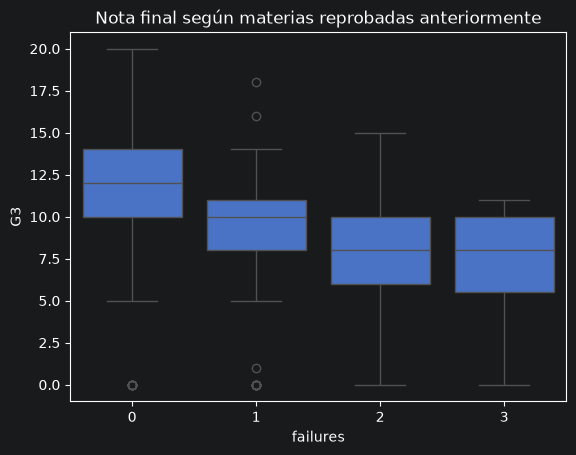

In [16]:
#Nota final según la cantidad de materias reprobadas anteriormente (failures)
sns.boxplot(x='failures', y='G3', data=df)
plt.title('Nota final según materias reprobadas anteriormente')
plt.show()

In [17]:
#Promedio de G3 y porcentaje de reprobados (G3 < 10) por cada factor
def resumen_por(columna):
    return df.groupby(columna).agg(estudiantes=('G3','size'),
                                   promedio_G3=('G3','mean'),
                                   porcentaje_reprueba=('G3', lambda x: (x < 10).mean() * 100))

resumen_por('failures')

,estudiantes,promedio_G3,porcentaje_reprueba
failures,,,
0,861,12.054588,14.982578
1,120,8.425000,48.333333
2,33,7.484848,66.666667
3,30,6.800000,70.000000


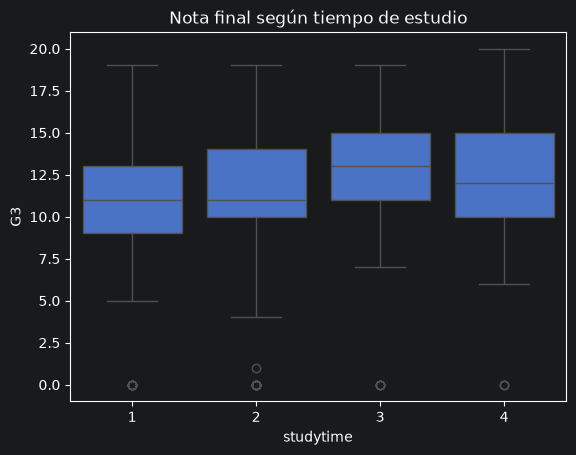

,estudiantes,promedio_G3,porcentaje_reprueba
studytime,,,
1,317,10.580442,27.444795
2,503,11.335984,22.067594
3,162,12.493827,14.197531
4,62,12.274194,14.516129


In [18]:
#Tiempo de estudio semanal: 1 = <2 h, 2 = 2-5 h, 3 = 5-10 h, 4 = >10 h
sns.boxplot(x='studytime', y='G3', data=df)
plt.title('Nota final según tiempo de estudio')
plt.show()
resumen_por('studytime')

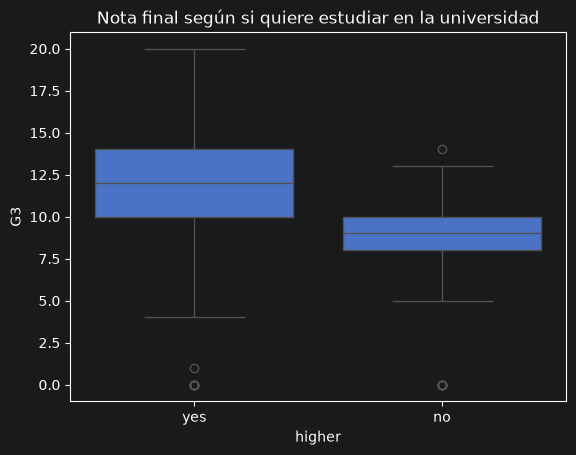

,estudiantes,promedio_G3,porcentaje_reprueba
higher,,,
no,89,8.348315,51.685393
yes,955,11.620942,19.267016


In [19]:
#¿El estudiante quiere seguir estudiando después del colegio?
sns.boxplot(x='higher', y='G3', data=df)
plt.title('Nota final según si quiere estudiar en la universidad')
plt.show()
resumen_por('higher')

In [20]:
#Apoyo educativo extra del colegio (schoolsup) y clases pagadas (paid)
resumen_por('schoolsup')

,estudiantes,promedio_G3,porcentaje_reprueba
schoolsup,,,
no,925,11.451892,21.513514
yes,119,10.487395,26.050420


In [21]:
resumen_por('paid')

,estudiantes,promedio_G3,porcentaje_reprueba
paid,,,
no,824,11.440534,20.631068
yes,220,10.972727,27.272727


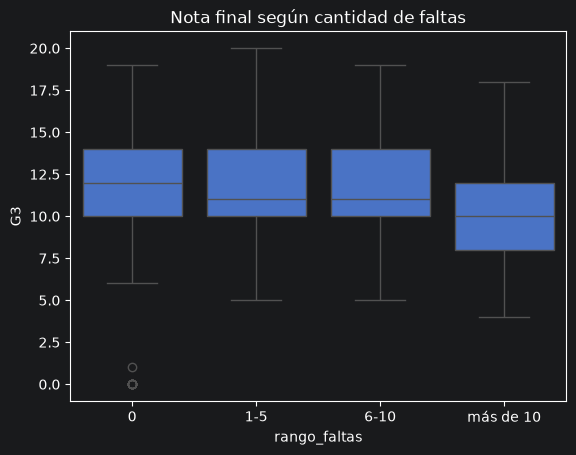

,estudiantes,promedio_G3,porcentaje_reprueba
rango_faltas,,,
0,359,10.888579,23.398329
1-5,368,11.907609,16.576087
6-10,202,11.673267,21.287129
más de 10,115,10.365217,36.521739


In [22]:
#Agrupamos las faltas en rangos para comparar
df['rango_faltas'] = pd.cut(df['absences'], bins=[-1, 0, 5, 10, 100], labels=['0', '1-5', '6-10', 'más de 10'])
sns.boxplot(x='rango_faltas', y='G3', data=df)
plt.title('Nota final según cantidad de faltas')
plt.show()
resumen_por('rango_faltas')

**Observaciones de los factores académicos**

- **Materias reprobadas antes (failures)** es el factor académico más fuerte: sin reprobadas el promedio es 12.1 y reprueba el 15 %; con 1 reprobada el promedio baja a 8.4 y reprueba el 48 %; con 3, reprueba el 70 %.
- **Querer ir a la universidad (higher):** quienes no quieren tienen un promedio de 8.4 y reprueba el 52 %, contra 11.6 y 19 % de quienes sí quieren.
- **Tiempo de estudio:** a más horas, mejor nota (10.6 con menos de 2 h contra 12.5 con 5 a 10 h), aunque la diferencia es moderada.
- **Faltas:** con más de 10 faltas reprueba el 36.5 %. El grupo con 0 faltas tiene un promedio más bajo de lo esperado porque ahí están los 53 estudiantes con nota 0, que no registran faltas.
- **Apoyo extra y clases pagadas** se asocian con notas un poco más bajas, probablemente porque esos apoyos se dan a estudiantes que ya tenían dificultades.

# 7.Factores familiares y sociales

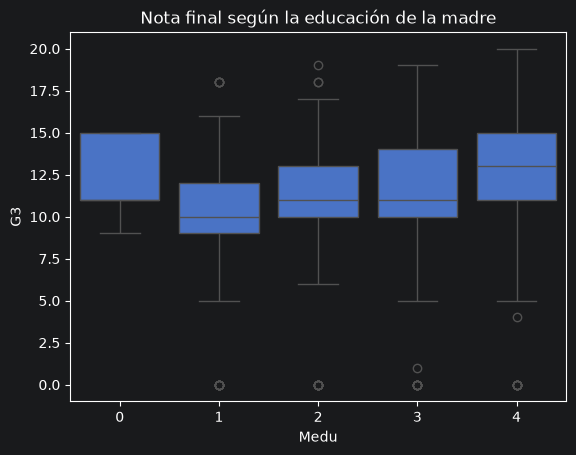

,estudiantes,promedio_G3,porcentaje_reprueba
Medu,,,
0,9,12.111111,11.111111
1,202,10.178218,30.693069
2,289,10.972318,21.799308
3,238,11.247899,23.949580
4,306,12.509804,15.359477


In [23]:
#Educación de la madre: 0 = ninguna, 1 = primaria, 2 = 5° a 9°, 3 = secundaria, 4 = superior
sns.boxplot(x='Medu', y='G3', data=df)
plt.title('Nota final según la educación de la madre')
plt.show()
resumen_por('Medu')

In [24]:
resumen_por('Fedu')

,estudiantes,promedio_G3,porcentaje_reprueba
Fedu,,,
0,9,12.333333,0.000000
1,256,10.367188,31.250000
2,324,11.243827,21.296296
3,231,11.636364,18.614719
4,224,12.254464,16.964286


In [25]:
#Acceso a internet en la casa
resumen_por('internet')

,estudiantes,promedio_G3,porcentaje_reprueba
internet,,,
no,217,10.534562,26.728111
yes,827,11.553809,20.798065


In [26]:
#Zona donde vive: U = urbana, R = rural
resumen_por('address')

,estudiantes,promedio_G3,porcentaje_reprueba
address,,,
R,285,10.600000,27.017544
U,759,11.620553,20.158103


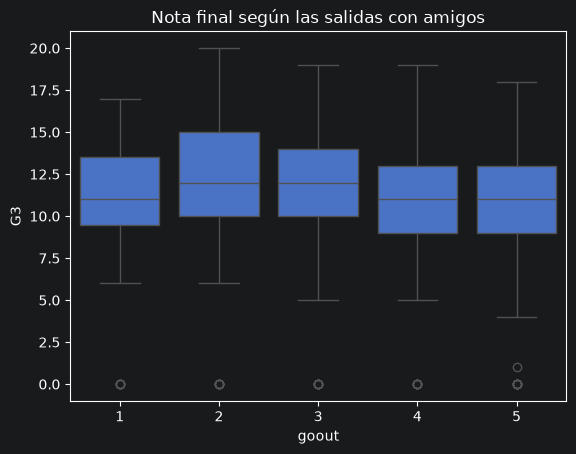

,estudiantes,promedio_G3,porcentaje_reprueba
goout,,,
1,71,10.450704,25.352113
2,248,12.056452,16.129032
3,335,11.689552,17.910448
4,227,11.092511,25.991189
5,163,10.276074,32.515337


In [27]:
#Salidas con amigos: 1 = muy pocas, 5 = muchísimas
sns.boxplot(x='goout', y='G3', data=df)
plt.title('Nota final según las salidas con amigos')
plt.show()
resumen_por('goout')

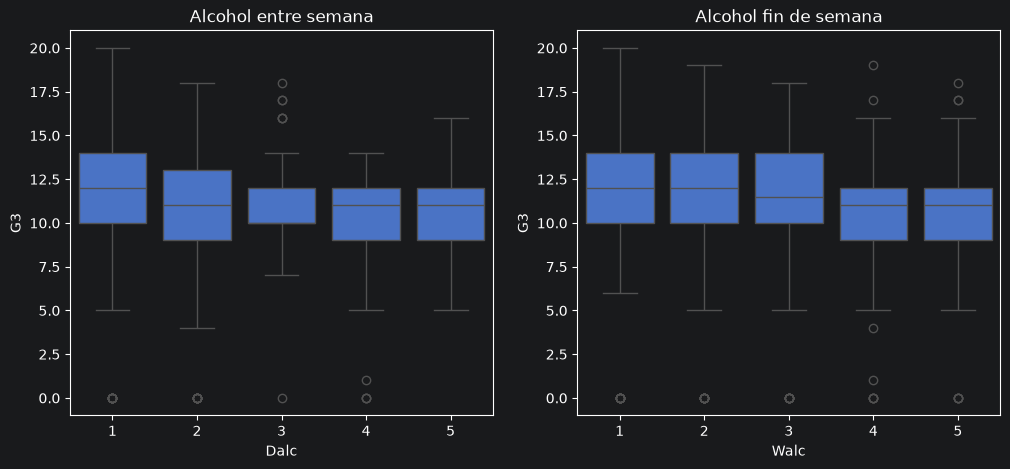

In [28]:
#Consumo de alcohol entre semana (Dalc) y fin de semana (Walc): 1 = muy bajo, 5 = muy alto
fig, axes = plt.subplots(1, 2, figsize=(12,5))
sns.boxplot(x='Dalc', y='G3', data=df, ax=axes[0])
axes[0].set_title('Alcohol entre semana')
sns.boxplot(x='Walc', y='G3', data=df, ax=axes[1])
axes[1].set_title('Alcohol fin de semana')
plt.show()

In [29]:
resumen_por('Dalc')

resumen_por('romantic')


,estudiantes,promedio_G3,porcentaje_reprueba
romantic,,,
no,673,11.624071,19.613670
yes,371,10.830189,26.415094


In [30]:
resumen_por('romantic')

,estudiantes,promedio_G3,porcentaje_reprueba
romantic,,,
no,673,11.624071,19.613670
yes,371,10.830189,26.415094


**Observaciones de los factores familiares y sociales**

- **Educación de los padres:** cuando la madre tiene educación superior (Medu = 4), el promedio es 12.5 y reprueba el 15 %; con solo primaria (Medu = 1), el promedio baja a 10.2 y reprueba el 31 %. Con el padre pasa algo parecido.
- **Internet y zona:** los estudiantes sin internet en casa o de zona rural tienen notas un poco más bajas (10.5 y 10.6) que quienes tienen internet o viven en zona urbana (11.6).
- **Salidas con amigos:** salir poco o moderado (nivel 2-3) se asocia con mejores notas; quienes salen muchísimo (nivel 5) tienen un promedio de 10.3 y reprueba el 32.5 %.
- **Consumo de alcohol:** a mayor consumo, menor nota. Con consumo muy bajo entre semana reprueba el 19 %, y con consumo alto (nivel 4) reprueba el 38.5 %.
- **Relación de pareja:** quienes tienen pareja tienen un promedio un poco menor (10.8 contra 11.6).
- En general, estos factores tienen un efecto **menor** que los académicos (materias reprobadas y querer ir a la universidad).

# 8.Correlación con la nota final

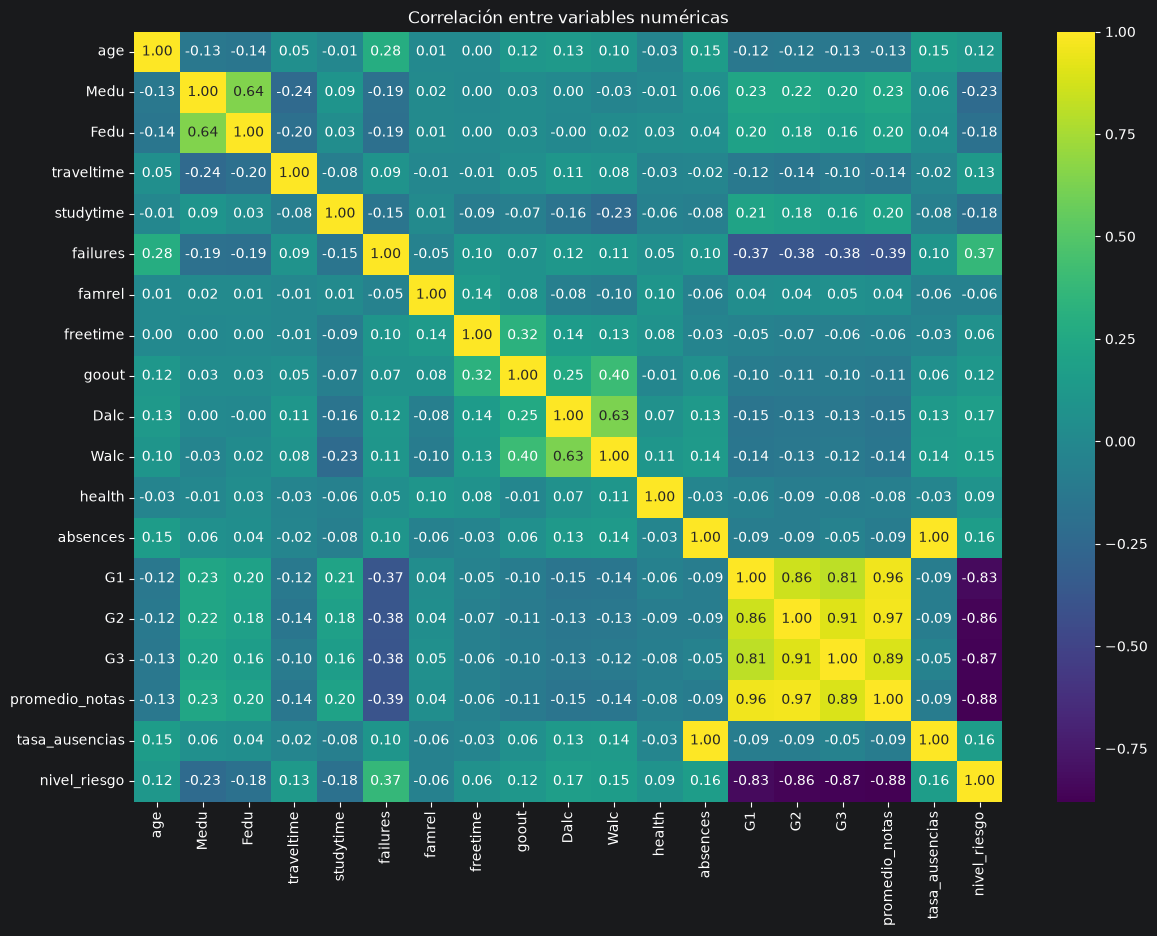

In [31]:
#Mapa de calor de correlación entre las variables numéricas
plt.figure(figsize=(14,10))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='viridis')
plt.title('Correlación entre variables numéricas')
plt.show()

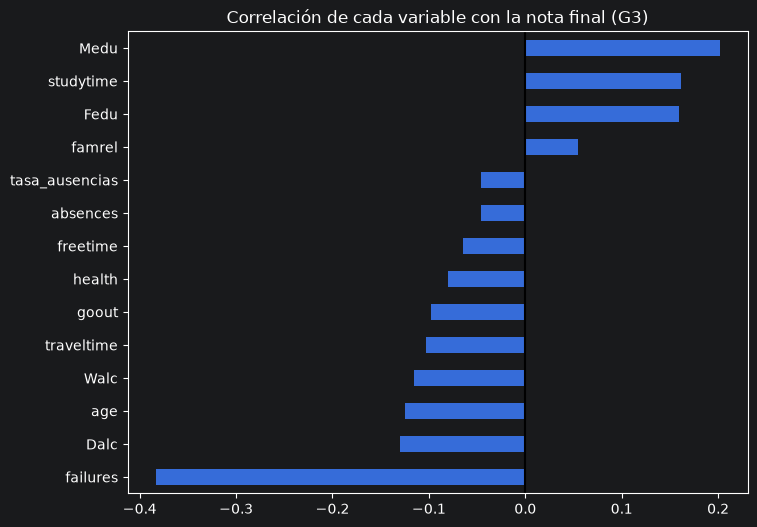

failures         -0.383145
Dalc             -0.129642
age              -0.125282
Walc             -0.115740
traveltime       -0.102627
goout            -0.097877
health           -0.080079
freetime         -0.064890
absences         -0.045671
tasa_ausencias   -0.045671
famrel            0.054461
Fedu              0.159796
studytime         0.161629
Medu              0.201472
Name: G3, dtype: float64

In [32]:
#Correlación con G3 sin las notas parciales ni las variables calculadas a partir de G3
#(sirve para ver qué factores pueden anticipar la nota antes de tener notas del año)
correlacion = df.corr(numeric_only=True)['G3'].drop(['G3','G1','G2','promedio_notas','nivel_riesgo']).sort_values()
correlacion.plot(kind='barh', figsize=(8,6))
plt.title('Correlación de cada variable con la nota final (G3)')
plt.axvline(0, color='black')
plt.show()
correlacion

**Observaciones de la correlación**

- Las notas parciales G1 y G2 son las variables más relacionadas con G3 (0.81 y 0.91).
- Sin las notas parciales, la variable con mayor relación es **failures** (-0.38): haber reprobado materias antes es el mejor indicador de riesgo.
- Le siguen la educación de la madre (Medu, 0.20) y del padre (Fedu, 0.16) y el tiempo de estudio (studytime, 0.16), con relación positiva.
- El consumo de alcohol (Dalc -0.13, Walc -0.12), la edad (-0.13) y las salidas (goout -0.10) tienen una relación negativa débil.
- Todas estas correlaciones son débiles, lo que explica por qué el Modelo 1 sin G1/G2 tiene un error mucho mayor.

# 9.Conclusiones del EDA

**Conclusiones: factores que más impactan el rendimiento académico**

1. **Notas parciales (G1 y G2):** son el mejor predictor de la nota final (correlación 0.81 y 0.91). El 88 % de los estudiantes termina a un punto o menos de su nota del segundo periodo.

2. **Materias reprobadas anteriormente (failures):** es el factor más importante sin contar las notas. Con una o más materias reprobadas, el porcentaje de reprobados pasa del 15 % a entre 48 % y 70 %.

3. **Querer ir a la universidad (higher):** quienes no quieren seguir estudiando reprueban en un 52 %, contra un 19 % de quienes sí quieren.

4. **La materia:** matemáticas es más difícil (promedio 10.4 y 33 % de reprobados) que portugués (11.9 y 15 %).

5. **Factores familiares y sociales:** la educación de los padres, el tiempo de estudio, el acceso a internet, las salidas frecuentes y el consumo de alcohol tienen influencia, pero más débil.

6. **Estudiantes con nota final 0:** 53 estudiantes (5 %) terminan con 0, aunque muchos tenían notas durante el año. Probablemente abandonaron y son los casos más difíciles de anticipar.

**Implicaciones para el proyecto:**

- Para una **alerta temprana** (sin G1 ni G2), los mejores indicadores son las materias reprobadas, querer o no ir a la universidad, la materia y la educación de los padres. Como su relación con la nota es débil, el Modelo 1 sin notas parciales tiene un error mayor.

- Estos factores también sirven para las **recomendaciones de intervención** del sistema: por ejemplo, tutorías para estudiantes con materias reprobadas, orientación vocacional para quienes no quieren seguir estudiando, y seguimiento de faltas y de hábitos sociales.
